In [35]:
import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
from load_industries import estimation_inputs, load_industry_returns
from matplotlib.axes import Axes
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.figure import Figure


In [52]:
def plot_portfolio(
    w: np.ndarray, 
    industry_names: list[str],
    title: str
) -> None:
    _, ax = plt.subplots(figsize=(7, 8))
    ax.barh(industry_names, w * 100)
    ax.invert_yaxis()  # first industry at the top
    ax.set_xlabel("Weight (%)")
    ax.set_title(title)
    ax.grid(True)
    plt.show()

In [53]:
R = load_industry_returns("30_Industry_Portfolios.csv")
mu, Sigma, names = estimation_inputs(R, start="2015-01", end="2024-12")
n = len(names)

print(f"Loaded {R.shape[1]} industries, {R.index[0]} to {R.index[-1]}")
print(f"mu: {mu.shape}, Sigma: {Sigma.shape}")

Loaded 30 industries, 1926-07 to 2026-08
mu: (30,), Sigma: (30, 30)


## Excercise 1a

We reproduce the solution for the greedy problem:


$$
\begin{aligned}
\underset{w \in \mathbb{R}^{n}}{\text{maximise}} \quad & \mu^\top w \\
\text{subject to} \quad & \mathbf{1}^\top w = 1, \\
& w \ge 0, \\
& w^ \top \Sigma w \leq \sigma_\text{eq}^2.
\end{aligned}
$$

In [54]:
# Initialize greedy optimization weights
greedy_w = cp.Variable(n)

# Build ingredients for objective function
portfolio_return = mu.T @ greedy_w
portfolio_risk = cp.quad_form(greedy_w, Sigma)
equal_weights = np.ones(n)*(1/n)
equal_weight_risk = equal_weights.T @ Sigma @ equal_weights
equal_weight_return = mu.T @ equal_weights

# Build constraints
normality = (cp.sum(greedy_w) == 1)
non_negativity = (greedy_w >= 0)
max_risk = (portfolio_risk <= equal_weight_risk)

greedy_constraints = [normality, non_negativity, max_risk]

# Build greedy objective
greedy_objective = cp.Maximize(portfolio_return)

# Build the optimization problem excluding risk
greedy_problem = cp.Problem(
    objective = greedy_objective,
    constraints = greedy_constraints
)

# Solve the greedy optimization problem
greedy_opt_return = greedy_problem.solve()
greedy_return = portfolio_return.value
greedy_risk = portfolio_risk.value

# print(greedy_w.value)

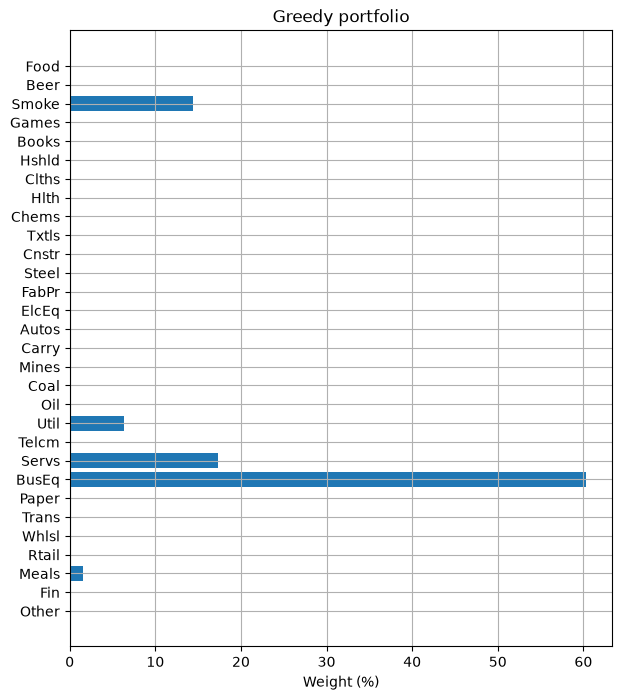

In [56]:
plot_portfolio(
    w = greedy_w.value, 
    industry_names=names,
    title="Greedy portfolio"
)

We can construct an efficient risk / return frontier by solving the following problem for various values of $\gamma$:

$$
\begin{aligned}
\underset{w \in \mathbb{R}^{n}}{\text{maximise}} \quad & \mu^\top w - \gamma \, w^\top \Sigma \, w \\
\text{subject to} \quad & \mathbf{1}^\top w = 1, \\
& w \ge 0, \\
& w^ \top \Sigma w \leq \sigma_\text{eq}^2.
\end{aligned}
$$

In [40]:
# Creating efficient frontier
m = 100
gammas = np.logspace(-1, 3, 100)
efficient_weights = np.zeros((m, n))
efficient_returns = np.zeros(m)
efficient_risks = np.zeros(m)

# Initialize efficient optimization weights
w_gamma = cp.Variable(n)

# Build ingredients for objective function
portfolio_return_gamma = mu.T @ w_gamma
portfolio_risk_gamma = cp.quad_form(w_gamma, Sigma)

# Build constraints
normality_gamma = (cp.sum(w_gamma) == 1)
non_negativity_gamma = (w_gamma >= 0)
max_risk_gamma = (portfolio_risk_gamma <= equal_weight_risk)

efficient_constraints = [normality_gamma, non_negativity_gamma, max_risk_gamma]
# efficient_constraints = [normality_gamma, non_negativity_gamma]

for g, gamma in enumerate(gammas):
    # Build efficient objective
    efficient_objective = cp.Maximize(portfolio_return_gamma - gamma * portfolio_risk_gamma)

    # Build the optimization problem excluding risk
    efficient_problem = cp.Problem(
        objective = efficient_objective,
        constraints = efficient_constraints
    )

    # Solve the efficient optimization problem
    efficient_opt_return = efficient_problem.solve()

    # Store results
    efficient_weights[g, :] = w_gamma.value
    efficient_returns[g] = portfolio_return_gamma.value
    efficient_risks[g] = portfolio_risk_gamma.value

In [41]:
def plot_frontier(
    risks: np.ndarray,
    returns: np.ndarray,
    params: np.ndarray,
    param_label: str = r"$\gamma$",
    cmap: str = "GnBu",
    label: str | None = None,
    ax: Axes | None = None,
) -> tuple[Figure, Axes]:
    # Plot a frontier, markers coloured by its parameter; draws on ax if given
    if ax is None:
        fig, ax = plt.subplots(figsize=(14, 7))
    else:
        fig = ax.figure

    ax.plot(risks, returns, color="black", linewidth=1, zorder=1)

    points = ax.scatter(
        risks, returns,
        c=params, 
        cmap=cmap, 
        norm=LogNorm(), 
        s=40, 
        edgecolors="black", 
        linewidths=0.5,
        zorder = 2,
        label=label,
    )

    fig.colorbar(points, ax=ax, label=param_label)
    ax.set_xlabel("Variance")
    ax.set_ylabel("Return")
    ax.grid(True)

    return fig, ax

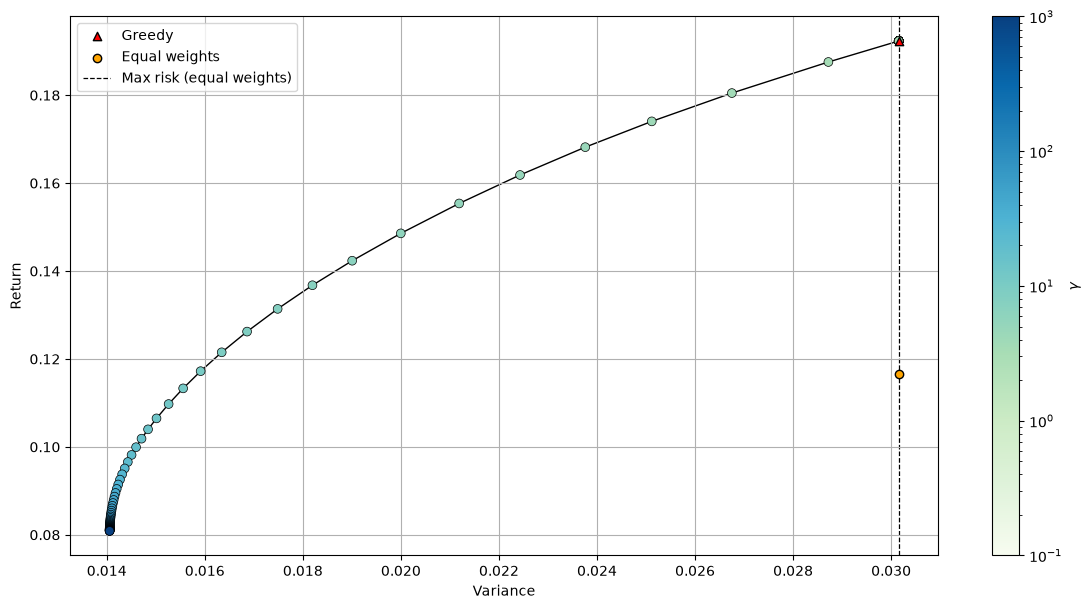

In [42]:
fig, ax = plot_frontier(efficient_risks, efficient_returns, gammas)

ax.scatter(greedy_risk, greedy_return, label = 'Greedy', color = 'red', marker = '^', zorder = 3, edgecolors= 'black')
ax.scatter(equal_weight_risk, equal_weight_return, label = 'Equal weights', color = 'orange', marker = 'o', zorder = 3, edgecolors= 'black')
ax.axvline(x = equal_weight_risk, linestyle = '--', color = 'black', linewidth = 0.9, zorder = -1, label = 'Max risk (equal weights)')
ax.legend()
plt.show()

## Excercise 1b & 1c

To include diversification into the weights, we add a convex penalty to the objective in the form of the $\beta \sum_i w_i^2$. The optimal solution of this term in isolation would be to evenly spread all weights. We show this by minimizing the following lagrangian:

\begin{equation*}
    \mathcal{L(w, \nu)} = \beta \sum_i w_i^2 - (\nu \sum_i w_i - 1).
\end{equation*}

We then have

\begin{equation*}
    \frac{\partial \mathcal{L}}{\partial w_i}= 2 \beta w_i - \nu = 0, \quad \forall i.
\end{equation*}

Thus

\begin{equation*}
w_i = \frac{\nu}{2 \beta}, \quad \forall i.
\end{equation*}

We therefore move to solving the convex problem:

$$
\begin{aligned}
\underset{w \in \mathbb{R}^{n}}{\text{maximise}} \quad & \mu^\top w - \beta \sum_i w_i^2 \\
\text{subject to} \quad & \mathbf{1}^\top w = 1, \\
& w \ge 0, \\
& w^ \top \Sigma w \leq \sigma_\text{eq}^2.
\end{aligned}
$$

In [43]:
# Creating diversification frontier
m = 100
betas = np.logspace(-1, 2, 100)
diversification_weights = np.zeros((m, n))
diversification_returns = np.zeros(m)
diversification_risks = np.zeros(m)

# Initialize diversification optimization weights
w_beta = cp.Variable(n)

# Build ingredients for objective function
portfolio_return_beta = mu.T @ w_beta
portfolio_risk_beta = cp.quad_form(w_beta, Sigma)
portfolio_diversification_beta = cp.sum_squares(w_beta)

# Build constraints
normality_beta = (cp.sum(w_beta) == 1)
non_negativity_beta = (w_beta >= 0)
max_risk_beta = (portfolio_risk_beta <= equal_weight_risk)

diversification_constraints = [normality_beta, non_negativity_beta, max_risk_beta]
# diversification_constraints = [normality_beta, non_negativity_beta]

for b, beta in enumerate(betas):
    # Build diversification objective
    diversification_objective = cp.Maximize(portfolio_return_beta - beta * portfolio_diversification_beta)

    # Build the optimization problem excluding risk
    diversification_problem = cp.Problem(
        objective = diversification_objective,
        constraints = diversification_constraints
    )

    # Solve the diversification optimization problem
    diversification_opt_return = diversification_problem.solve()

    # Store results
    diversification_weights[b, :] = w_beta.value
    diversification_returns[b] = portfolio_return_beta.value
    diversification_risks[b] = portfolio_risk_beta.value

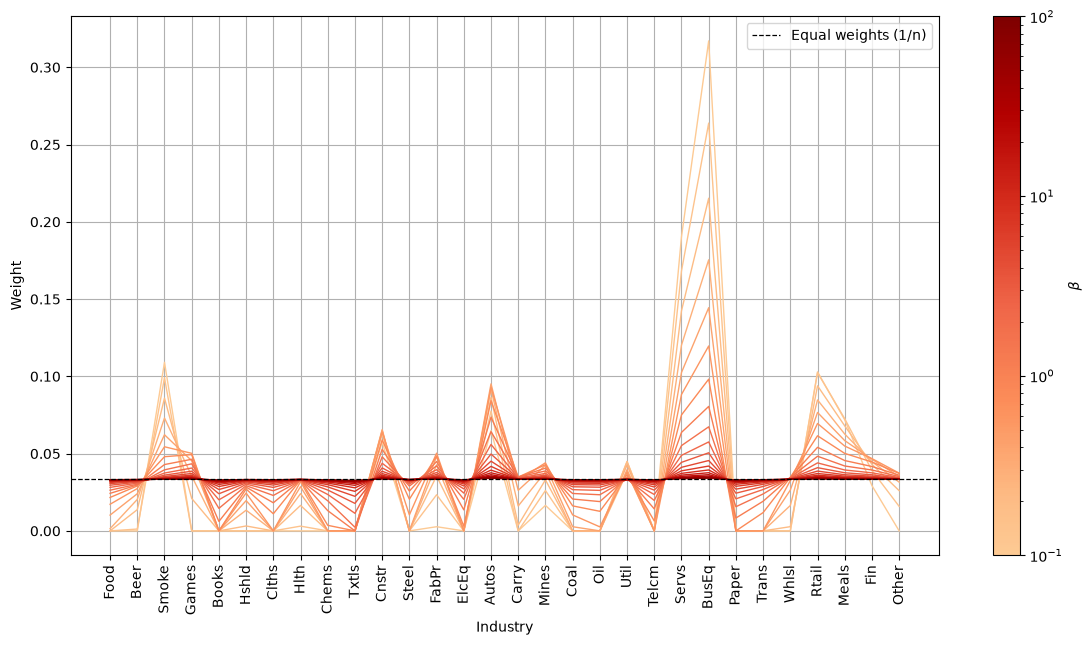

In [44]:
# Plot the weights per industry, one line for every j-th beta, coloured by beta
j = 5
norm = LogNorm(vmin=betas.min(), vmax=betas.max())
cmap = ListedColormap(plt.get_cmap("OrRd")(np.linspace(0.3, 1, 256)))  # skip the near-white start of GnBu

fig, ax = plt.subplots(figsize=(14, 7))
for beta, w in zip(betas[::j], diversification_weights[::j]):
    ax.plot(names, w, color=cmap(norm(beta)), linewidth=1)

ax.axhline(1 / n, linestyle="--", color="black", linewidth=0.9, label="Equal weights (1/n)")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=r"$\beta$")
ax.set_xlabel("Industry")
ax.set_ylabel("Weight")
ax.tick_params(axis="x", rotation=90)
ax.grid(True)
ax.legend()
plt.show()

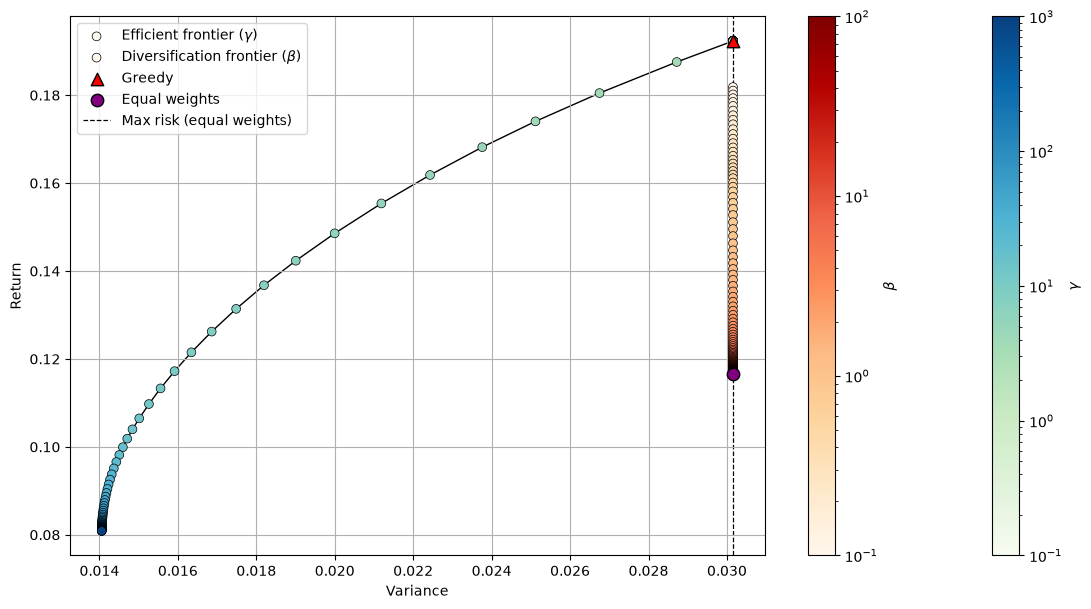

In [45]:
# Efficient (gamma) and diversification (beta) frontiers in one plot
fig, ax = plot_frontier(efficient_risks, efficient_returns, gammas, label=r"Efficient frontier ($\gamma$)")
plot_frontier(diversification_risks, diversification_returns, betas,
              param_label=r"$\beta$", cmap="OrRd", label=r"Diversification frontier ($\beta$)", ax=ax)

ax.scatter(greedy_risk, greedy_return, label = 'Greedy', color = 'red', marker = '^', s = 80, zorder = 3, edgecolors= 'black')
ax.scatter(equal_weight_risk, equal_weight_return, label = 'Equal weights', color = 'purple', marker = 'o', s = 80, zorder = 3, edgecolors= 'black')
ax.axvline(x = equal_weight_risk, linestyle = '--', color = 'black', linewidth = 0.9, zorder = -1, label = 'Max risk (equal weights)')
ax.legend()
plt.show()

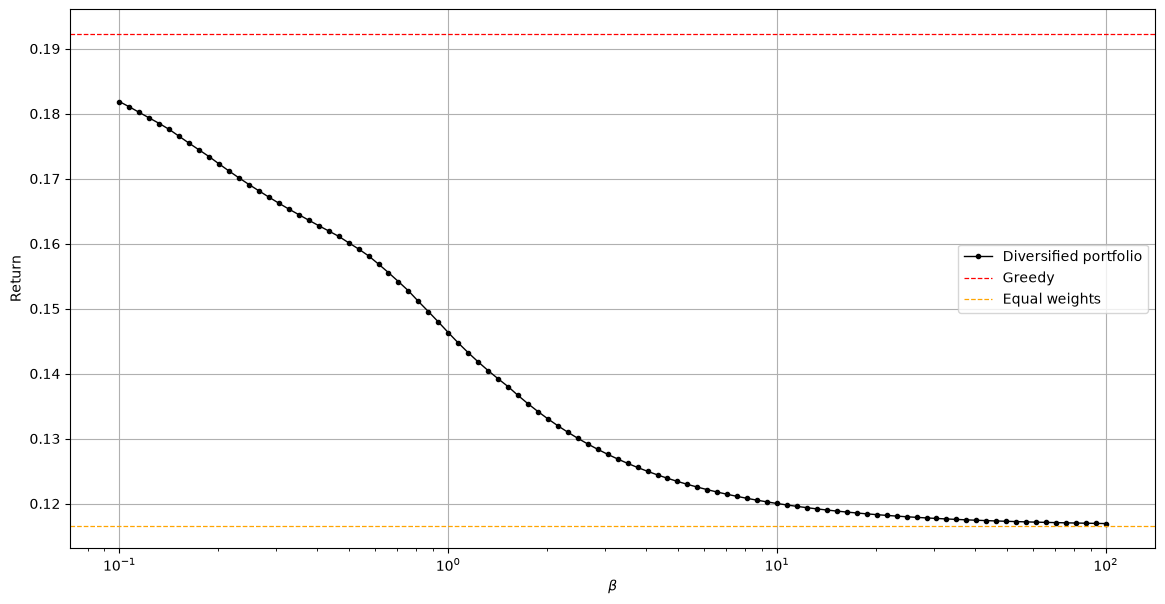

In [46]:
# Expected return as a function of beta
fig, ax = plt.subplots(figsize=(14, 7))

ax.plot(betas, diversification_returns, color="black", linewidth=1, marker=".", label="Diversified portfolio")
ax.axhline(greedy_return, linestyle="--", color="red", linewidth=0.9, label="Greedy")
ax.axhline(equal_weight_return, linestyle="--", color="orange", linewidth=0.9, label="Equal weights")

ax.set_xscale("log")
ax.set_xlabel(r"$\beta$")
ax.set_ylabel("Return")
ax.grid(True)
ax.legend()
plt.show()

## Bonus
We now solve the full problem:

$$
\begin{aligned}
\underset{w \in \mathbb{R}^{n}}{\text{maximise}} \quad & \mu^\top w - \gamma \, w^\top \Sigma \, w - \beta \sum_i w_i^2 \\
\text{subject to} \quad & \mathbf{1}^\top w = 1, \\
& w \ge 0, \\
& w^ \top \Sigma w \leq \sigma_\text{eq}^2.
\end{aligned}
$$

for a grid of values for $\gamma, \beta$

In [ ]:
# Solve the combined problem on a (gamma, beta) grid
gridsize_beta = 100
gridsize_gamma = 100
gamma_grid = np.logspace(-1, 3, gridsize_gamma)
beta_grid = np.logspace(-3, 2, gridsize_beta)

# Build the problem once; gamma and beta are parameters so CVXPY can re-solve quickly
gamma_par = cp.Parameter(nonneg=True)
beta_par = cp.Parameter(nonneg=True)
w_full = cp.Variable(n)

portfolio_return_full = mu.T @ w_full
portfolio_risk_full = cp.quad_form(w_full, Sigma)
portfolio_diversification_full = cp.sum_squares(w_full)

full_constraints = [
    cp.sum(w_full) == 1,
    w_full >= 0,
    portfolio_risk_full <= equal_weight_risk,
]
full_problem = cp.Problem(
    cp.Maximize(portfolio_return_full - gamma_par * portfolio_risk_full - beta_par * portfolio_diversification_full),
    full_constraints,
)

# Rows: beta, columns: gamma
full_returns = np.zeros((len(beta_grid), len(gamma_grid)))
full_risks = np.zeros((len(beta_grid), len(gamma_grid)))
full_weights = np.zeros((len(beta_grid), len(gamma_grid), n))

for b, beta in enumerate(beta_grid):
    for g, gamma in enumerate(gamma_grid):
        gamma_par.value = gamma
        beta_par.value = beta
        full_problem.solve()
        assert full_problem.status == cp.OPTIMAL, (gamma, beta, full_problem.status)

        full_returns[b, g] = portfolio_return_full.value
        full_risks[b, g] = portfolio_risk_full.value
        full_weights[b, g] = w_full.value

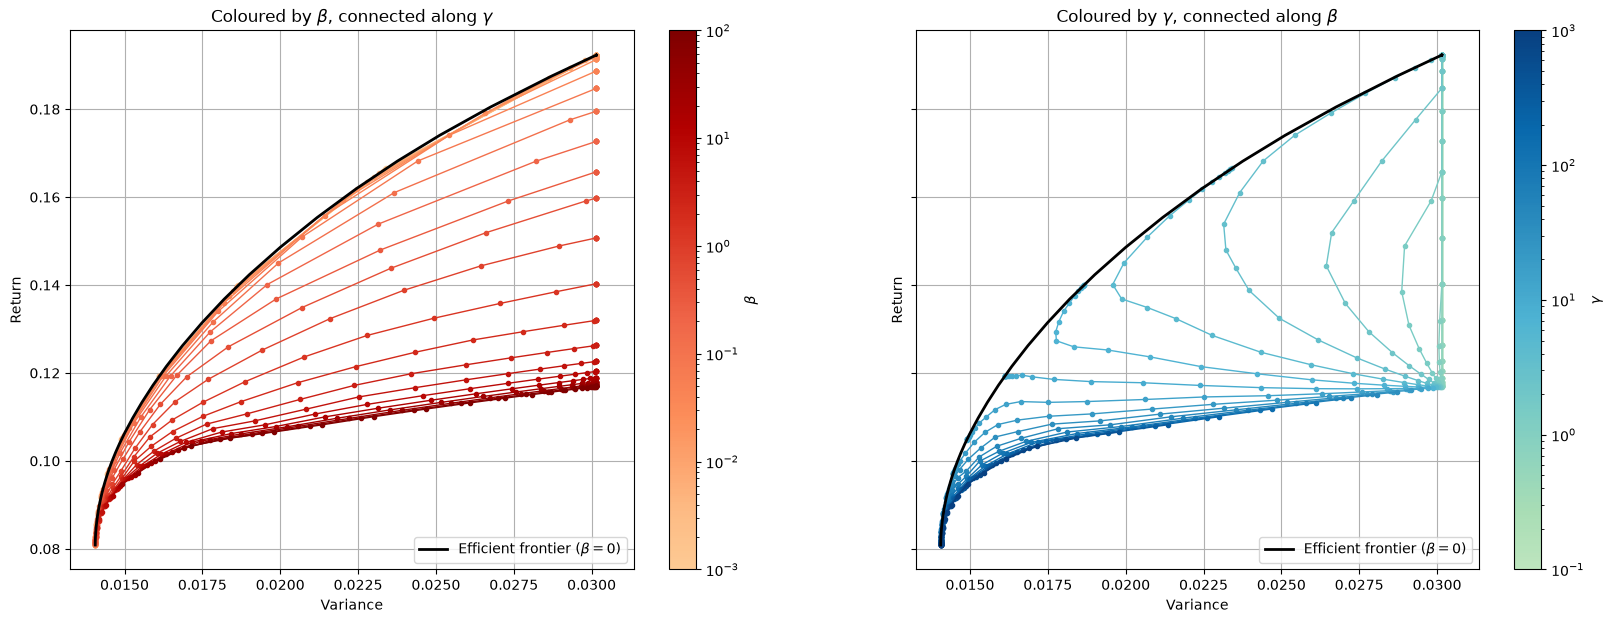

In [50]:
def plot_subfrontiers(
    ax: Axes,
    risks: np.ndarray,
    returns: np.ndarray,
    params: np.ndarray,
    param_label: str,
    cmap: str,
) -> None:
    # One line per row of risks/returns, coloured by the matching entry of params
    norm = LogNorm(vmin=params.min(), vmax=params.max())
    cmap = ListedColormap(plt.get_cmap(cmap)(np.linspace(0.3, 1, 256)))  # skip the near-white start
    for p, risk_row, return_row in zip(params, risks, returns):
        ax.plot(risk_row, return_row, color=cmap(norm(p)), marker=".", linewidth=1)
    ax.figure.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=param_label)
    ax.set_xlabel("Variance")
    ax.set_ylabel("Return")
    ax.grid(True)


fig, (ax_beta, ax_gamma) = plt.subplots(1, 2, figsize=(20, 7), sharex=True, sharey=True)

# Left: one curve per beta (connecting increasing gamma), coloured by beta
plot_subfrontiers(ax_beta, full_risks, full_returns, beta_grid, r"$\beta$", "OrRd")
ax_beta.set_title(r"Coloured by $\beta$, connected along $\gamma$")

# Right: one curve per gamma (connecting increasing beta), coloured by gamma
plot_subfrontiers(ax_gamma, full_risks.T, full_returns.T, gamma_grid, r"$\gamma$", "GnBu")
ax_gamma.set_title(r"Coloured by $\gamma$, connected along $\beta$")


ax_gamma.set_xlim(right=equal_weight_risk + 0.0012)

# True efficient frontier (beta = 0) in both panels
for ax in (ax_beta, ax_gamma):
    ax.plot(efficient_risks, efficient_returns, color="black", linewidth=2, zorder=3,
            label=r"Efficient frontier ($\beta = 0$)")
    ax.legend(loc="lower right")

plt.show()

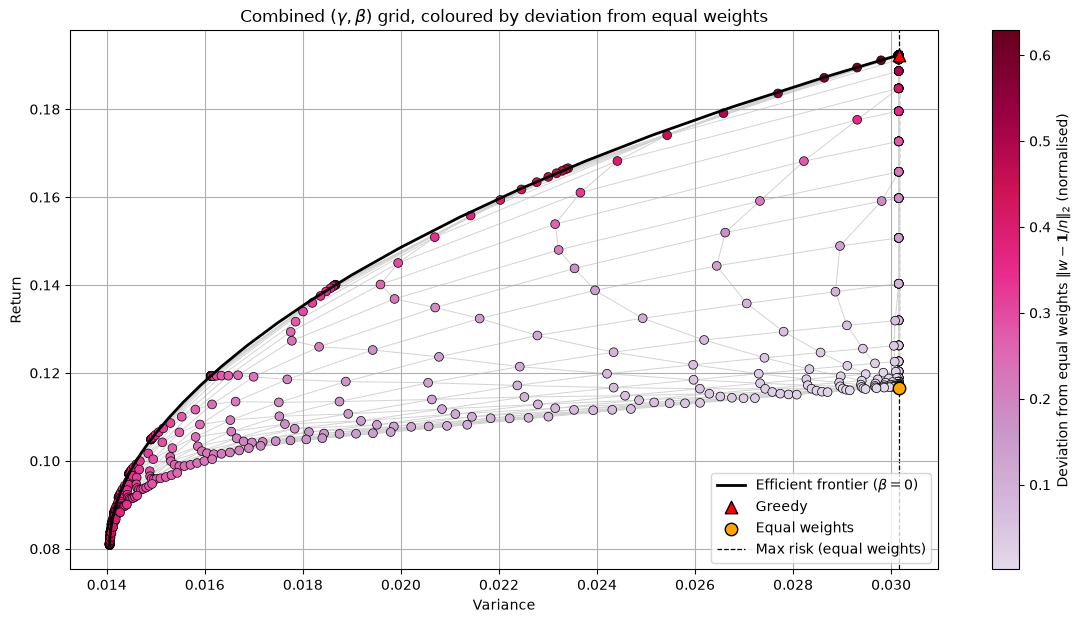

In [51]:
def deviation_from_equal(W: np.ndarray) -> np.ndarray:
    # Normalised L2 distance to 1/n along the last axis: 0 = equal weights, 1 = single asset
    n = W.shape[-1]
    return np.sqrt(np.maximum(np.sum(W**2, axis=-1) - 1 / n, 0) / (1 - 1 / n))


full_deviation = deviation_from_equal(full_weights)

fig, ax = plt.subplots(figsize=(14, 7))

# Faint (gamma, beta) mesh underneath, so the grid structure stays visible
for risk_row, return_row in zip(full_risks, full_returns):
    ax.plot(risk_row, return_row, color="lightgrey", linewidth=0.7, zorder=1)
for risk_col, return_col in zip(full_risks.T, full_returns.T):
    ax.plot(risk_col, return_col, color="lightgrey", linewidth=0.7, zorder=1)

cmap = ListedColormap(plt.get_cmap("PuRd")(np.linspace(0.15, 1, 256)))  # skip the near-white start
points = ax.scatter(
    full_risks.ravel(), full_returns.ravel(),
    c=full_deviation.ravel(),
    cmap=cmap,
    s=40,
    edgecolors="black",
    linewidths=0.5,
    zorder=2,
)
fig.colorbar(points, ax=ax, label=r"Deviation from equal weights $\|w - \mathbf{1}/n\|_2$ (normalised)")

ax.plot(efficient_risks, efficient_returns, color="black", linewidth=2, zorder=3, label=r"Efficient frontier ($\beta = 0$)")
ax.scatter(greedy_risk, greedy_return, label="Greedy", color="red", marker="^", s=80, zorder=4, edgecolors="black")
ax.scatter(equal_weight_risk, equal_weight_return, label="Equal weights", color="orange", marker="o", s=80, zorder=4, edgecolors="black")
ax.axvline(x=equal_weight_risk, linestyle="--", color="black", linewidth=0.9, zorder=0, label="Max risk (equal weights)")

ax.set_xlabel("Variance")
ax.set_ylabel("Return")
ax.set_title(r"Combined $(\gamma, \beta)$ grid, coloured by deviation from equal weights")
ax.grid(True)
ax.legend(loc="lower right")
plt.show()